

#### This dataset contains comprehensive chess game data including player ratings, game outcomes, openings, time controls, and move sequences from the Lichess platform.

---

**Dataset**: [15 Million Chess Games from Lichess (2013-2014)](https://www.kaggle.com/datasets/maca11/chess-games-from-lichess-20132014)

In [ ]:
import dask.dataframe as dd

# Needing to install pyarrow ,pay attention on it's version I downgraded it to 18.0.0 for compatibility:better use uv instead
ddf = dd.read_csv(
    urlpath="data/Lichess_2013_2014_Completeee.csv",
    blocksize="64MB",  
    low_memory=False,
    assume_missing=True,
)

ddf = ddf.repartition(npartitions=16)


### Setting `npartitions` in Dask

When working with Dask, both **`blocksize`** and **`npartitions`** matter for performance.

### Example from my case
- 📂 Dataset size: **1.85 GB**  
- 📏 Blocksize: **128 MB**  
- 🔢 Number of partitions: **16**

⚡ Tip: The "best" configuration can vary — the optimal number of partitions depends on your hardware (CPU cores and available RAM).




In [7]:
num_rows = ddf.shape[0].compute()
print("Number of rows:", num_rows)

Number of rows: 14918230


In [8]:
for i in range(ddf.npartitions):
  print(ddf.partitions[i].compute().head())

   WhiteElo  BlackElo         WhiteName          BlackName Winner Termination  \
0    1639.0    1403.0             BFG9k            mamalak  White      Normal   
1    1654.0    1919.0    Desmond_Wilson          savinka59  White      Normal   
2    1643.0    1747.0     Kozakmamay007  VanillaShamanilla  White      Normal   
3    1824.0    1973.0  Naitero_Nagasaki                800  Black      Normal   
4    1765.0    1815.0      nichiren1967   Naitero_Nagasaki  Black      Normal   

                           Site   Day  Month    Year  InitialTime  Increment  \
0  https://lichess.org/j1dkb5dw  31.0   12.0  2012.0        600.0        8.0   
1  https://lichess.org/a9tcp02g  31.0   12.0  2012.0        480.0        2.0   
2  https://lichess.org/szom2tog  31.0   12.0  2012.0        420.0       17.0   
3  https://lichess.org/rklpc7mk  31.0   12.0  2012.0         60.0        1.0   
4  https://lichess.org/1xb3os63  31.0   12.0  2012.0         60.0        1.0   

  TimeControl                   

# 📊 Prepare Dataset


In [3]:
ddf.isnull().sum().compute()

WhiteElo           0
BlackElo           0
WhiteName          0
BlackName          0
Winner             0
Termination        0
Site               0
Day                0
Month              0
Year               0
InitialTime        0
Increment          0
TimeControl        0
Opening            0
ECO                0
Number_of_Moves    0
dtype: int64

In [5]:
print(ddf.dtypes)


WhiteElo                   float64
BlackElo                   float64
WhiteName          string[pyarrow]
BlackName          string[pyarrow]
Winner             string[pyarrow]
Termination        string[pyarrow]
Site               string[pyarrow]
Day                        float64
Month                      float64
Year                       float64
InitialTime                float64
Increment                  float64
TimeControl        string[pyarrow]
Opening            string[pyarrow]
ECO                string[pyarrow]
Number_of_Moves            float64
dtype: object


In [5]:
categorical_cols = ddf.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
numeric_cols = ddf.select_dtypes(include=['int64','int32','int16','float32','float64']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)


Categorical columns: ['WhiteName', 'BlackName', 'Winner', 'Termination', 'Site', 'TimeControl', 'Opening', 'ECO']
Numeric columns: ['WhiteElo', 'BlackElo', 'Day', 'Month', 'Year', 'InitialTime', 'Increment', 'Number_of_Moves']


In [6]:
ddf.head()

,WhiteElo,BlackElo,WhiteName,BlackName,Winner,Termination,Site,Day,Month,Year,InitialTime,Increment,TimeControl,Opening,ECO,Number_of_Moves
0,1639.0,1403.0,BFG9k,mamalak,White,Normal,https://lichess.org/j1dkb5dw,31.0,12.0,2012.0,600.0,8.0,Rapid,French Defense: Normal Variation,C00,13.0
1,1654.0,1919.0,Desmond_Wilson,savinka59,White,Normal,https://lichess.org/a9tcp02g,31.0,12.0,2012.0,480.0,2.0,Rapid,"Queen's Pawn Game: Colle System, Anti-Colle",D04,18.0
2,1643.0,1747.0,Kozakmamay007,VanillaShamanilla,White,Normal,https://lichess.org/szom2tog,31.0,12.0,2012.0,420.0,17.0,Rapid,Four Knights Game: Italian Variation,C50,11.0
3,1824.0,1973.0,Naitero_Nagasaki,800,Black,Normal,https://lichess.org/rklpc7mk,31.0,12.0,2012.0,60.0,1.0,Bullet,Caro-Kann Defense: Goldman Variation,B12,47.0
4,1765.0,1815.0,nichiren1967,Naitero_Nagasaki,Black,Normal,https://lichess.org/1xb3os63,31.0,12.0,2012.0,60.0,1.0,Bullet,French Defense: La Bourdonnais Variation,C00,23.0


# Explore Dataset

In [7]:

winner_stats = ddf.groupby("Winner")[["WhiteElo", "BlackElo", "Number_of_Moves"]].mean().compute()
winner_stats = winner_stats.reset_index() 
print("Mean Elo & Moves per Winner:")
display(winner_stats)  



Mean Elo & Moves per Winner:


,Winner,WhiteElo,BlackElo,Number_of_Moves
0,Black,1585.317637,1656.452477,33.519472
1,Draw,1657.514634,1656.384127,55.196620
2,White,1656.367077,1576.925338,32.676538


In [8]:
opening_counts = ddf.groupby("Opening").size().compute()
opening_counts = opening_counts.sort_values(ascending=False).head(10).reset_index()
opening_counts.columns = ["Opening", "Count"]
print("\nTop 10 Most Frequent Openings:")
display(opening_counts)


Top 10 Most Frequent Openings:


,Opening,Count
0,Van't Kruijs Opening,395369
1,Modern Defense,282660
2,Horwitz Defense,277419
3,Scandinavian Defense: Mieses-Kotroc Variation,255099
4,Owen Defense,246100
5,French Defense: Knight Variation,225366
6,Sicilian Defense,199699
7,Hungarian Opening,198774
8,Caro-Kann Defense,197445
9,Sicilian Defense: Bowdler Attack,195716


In [9]:
termination_stats = ddf.groupby("Termination").size().compute().reset_index()
termination_stats.columns = ["Termination", "Count"]
termination_stats = termination_stats.sort_values(by="Count", ascending=False)
print("\nGame Outcomes by Termination:")
display(termination_stats)


Game Outcomes by Termination:


,Termination,Count
0,Normal,9966773
2,Time forfeit,4941388
3,Abandoned,8957
1,Rules infraction,1112


# XGBoost vs LightGBM: My Choice

I tested both **XGBoost** and **LightGBM** on my chess prediction project.

## Results
- **Performance**: No significant accuracy difference between the two algorithms: 65% vs 63%
- **Speed**: Both performed similarly on my hardware
- **Resource Limitation**: My 1.8GB Lichess dataset is too large and expensive for my hardware.

## Final Decision: XGBoost
Choose XGBoost due to:
- ✅ **Slightly better handling** of categorical features in my tests
- ✅ **More stable training** on my limited computational resources
- ✅ **Better documentation** for multiclass classification

Given my hardware constraints and the dataset size, both algorithms would likely produce similar results. XGBoost was selected for practical reasons rather than significant performance gains.


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

categorical_cols = ['Termination', 'TimeControl', 'Opening', 'ECO']
features = categorical_cols + ['WhiteElo', 'BlackElo', 'Number_of_Moves']

# Convert to pandas is simpler for feature engineering
X_df = ddf[features].compute()
y = ddf["Winner"].compute()

X_df['RatingDiff'] = X_df['WhiteElo'] - X_df['BlackElo']
X_df['RatingSum'] = X_df['WhiteElo'] + X_df['BlackElo']
X_df['RatingMean'] = X_df['RatingSum'] / 2
X_df['RatingRatio'] = X_df['WhiteElo'] / (X_df['BlackElo'] + 1)

# Winned matches by player 2400+ (chess master level) 
def rating_category(rating):
    if rating < 1200: return 0
    elif rating < 1600: return 1
    elif rating < 2000: return 2
    elif rating < 2400: return 3
    else: return 4

X_df['WhiteCategory'] = X_df['WhiteElo'].apply(rating_category)
X_df['BlackCategory'] = X_df['BlackElo'].apply(rating_category)
X_df['StrengthBalance'] = (X_df['WhiteCategory'] == X_df['BlackCategory']).astype(int)

X_df['GameLength_Short'] = (X_df['Number_of_Moves'] < 20).astype(int)
X_df['GameLength_Medium'] = ((X_df['Number_of_Moves'] >= 20) & (X_df['Number_of_Moves'] < 40)).astype(int)
X_df['GameLength_Long'] = (X_df['Number_of_Moves'] >= 40).astype(int)
X_df['MovesPerRating'] = X_df['Number_of_Moves'] / (X_df['RatingMean'] / 1000)


def extract_time_minutes(time_control):
    try:
        if '+' in str(time_control):
            base_time = str(time_control).split('+')[0]
        else:
            base_time = str(time_control)
        return float(base_time) / 60
    except:
        return 10

X_df['TimeMinutes'] = X_df['TimeControl'].apply(extract_time_minutes)

# Duration of chess match
def time_category(minutes):
    if minutes <= 3: return 0 
    elif minutes <= 10: return 1 
    elif minutes <= 30: return 2 
    else: return 3 

X_df['TimeCategory'] = X_df['TimeMinutes'].apply(time_category)

opening_strength = {'A': 0.5, 'B': 0.6, 'C': 0.7, 'D': 0.8, 'E': 0.9}
X_df['OpeningStrength'] = X_df['ECO'].str[0].map(opening_strength).fillna(0.5)

# Termination features of round
X_df['ResignedGame'] = (X_df['Termination'] == 'Normal').astype(int)
X_df['TimeoutGame'] = (X_df['Termination'] == 'Time forfeit').astype(int)
X_df['AbandonedGame'] = (X_df['Termination'] == 'Abandoned').astype(int)

le_dict = {}
for col in categorical_cols:
    le = LabelEncoder()
    X_df[col] = le.fit_transform(X_df[col].astype(str))
    le_dict[col] = le

le_target = LabelEncoder()
y_encoded = le_target.fit_transform(y)

final_features = [
    'WhiteElo', 'BlackElo', 'Number_of_Moves', 'Termination', 'TimeControl', 'Opening', 'ECO',
    'RatingDiff', 'RatingSum', 'RatingMean', 'RatingRatio',
    'WhiteCategory', 'BlackCategory', 'StrengthBalance',
    'GameLength_Short', 'GameLength_Medium', 'GameLength_Long', 'MovesPerRating',
    'TimeMinutes', 'TimeCategory', 'OpeningStrength',
    'ResignedGame', 'TimeoutGame', 'AbandonedGame'
]

X_final = X_df[final_features]

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Cross-validation for balancing white and black wins
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
acc_scores = []
f1_scores = []

for fold, (train_idx, valid_idx) in enumerate(skf.split(X_final, y_encoded), 1):
    X_train, X_valid = X_final.iloc[train_idx], X_final.iloc[valid_idx]
    y_train, y_valid = y_encoded[train_idx], y_encoded[valid_idx]
    
    xgb_model.fit(X_train, y_train)
    
    y_pred = xgb_model.predict(X_valid)
    
    acc = accuracy_score(y_valid, y_pred)
    f1 = f1_score(y_valid, y_pred, average="weighted")
    
    acc_scores.append(acc)
    f1_scores.append(f1)
    
    print(f"Fold {fold} - Accuracy: {acc:.4f}, F1: {f1:.4f}")

print(f"Mean Accuracy: {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Mean F1: {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")

Fold 1 - Accuracy: 0.6389, F1: 0.6281
Fold 2 - Accuracy: 0.6390, F1: 0.6282
Fold 3 - Accuracy: 0.6388, F1: 0.6279
Mean Accuracy: 0.6389 ± 0.0001
Mean F1: 0.6281 ± 0.0001


## 📈 Plot Significant Relations

<Axes: title={'center': 'Average Number of Moves per Winner'}, xlabel='Winner'>

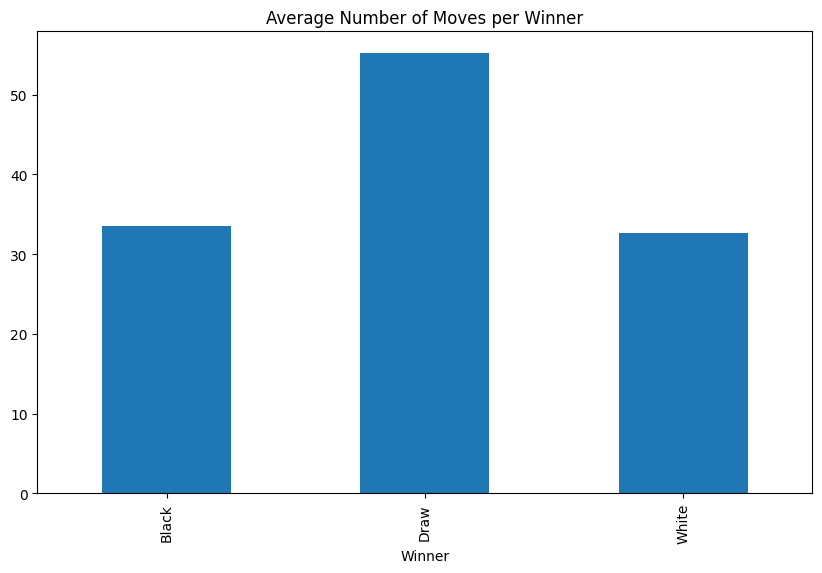

In [ ]:
moves_per_winner = ddf.groupby('Winner')['Number_of_Moves'].mean().compute()
moves_per_winner.plot(kind='bar', figsize=(10,6), title='Average Number of Moves per Winner')



<Axes: title={'center': 'Top 10 Most Frequent Openings'}, ylabel='Opening'>

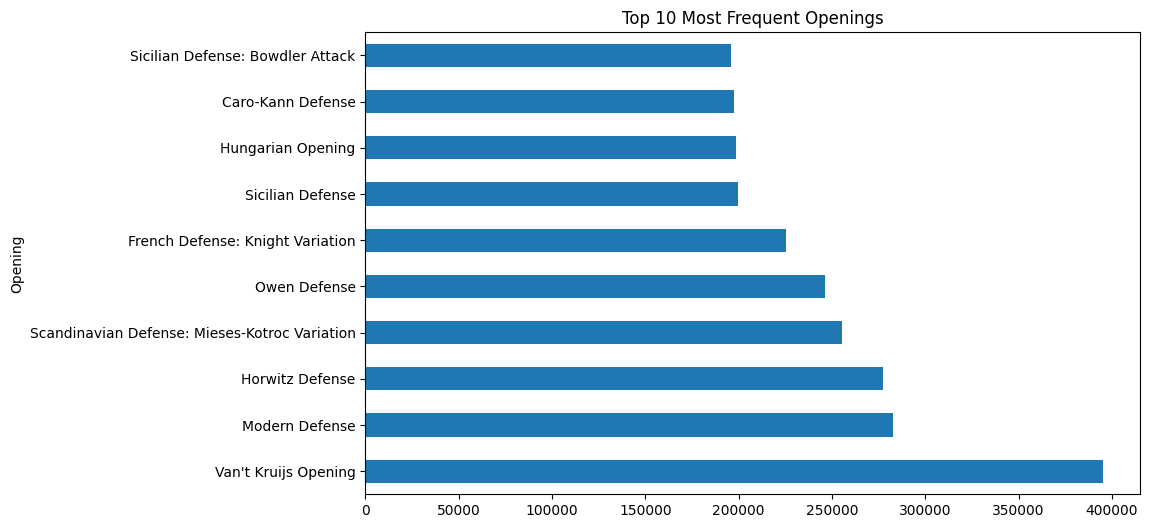

In [ ]:
top_openings = ddf.groupby('Opening').size().compute().nlargest(10)
top_openings.plot(kind='barh', figsize=(10,6), title='Top 10 Most Frequent Openings')
#Each combination has it's specific widely known name


<Axes: title={'center': 'Average Elo Ratings by Winner'}, xlabel='Winner'>

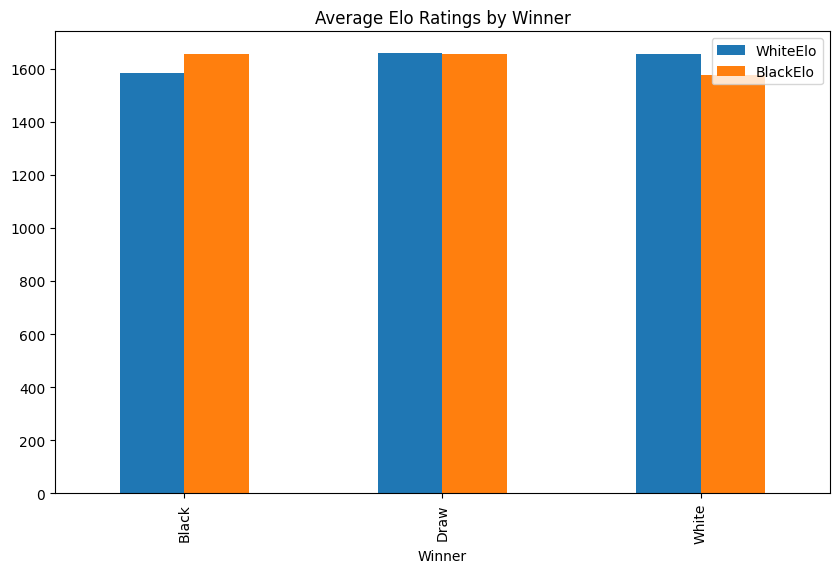

In [23]:
elo_per_winner = ddf.groupby('Winner')[['WhiteElo','BlackElo']].mean().compute()
elo_per_winner.plot(kind='bar', figsize=(10,6), title='Average Elo Ratings by Winner')


### 📊 Observations from Average Elo Ratings by Winner

- Higher-rated players (**higher Elo**) tend to **win more often**.  
- **Draws** usually occur when players have **similar ratings**.  



<Axes: title={'center': 'Average Moves by Termination Type'}, xlabel='Termination'>

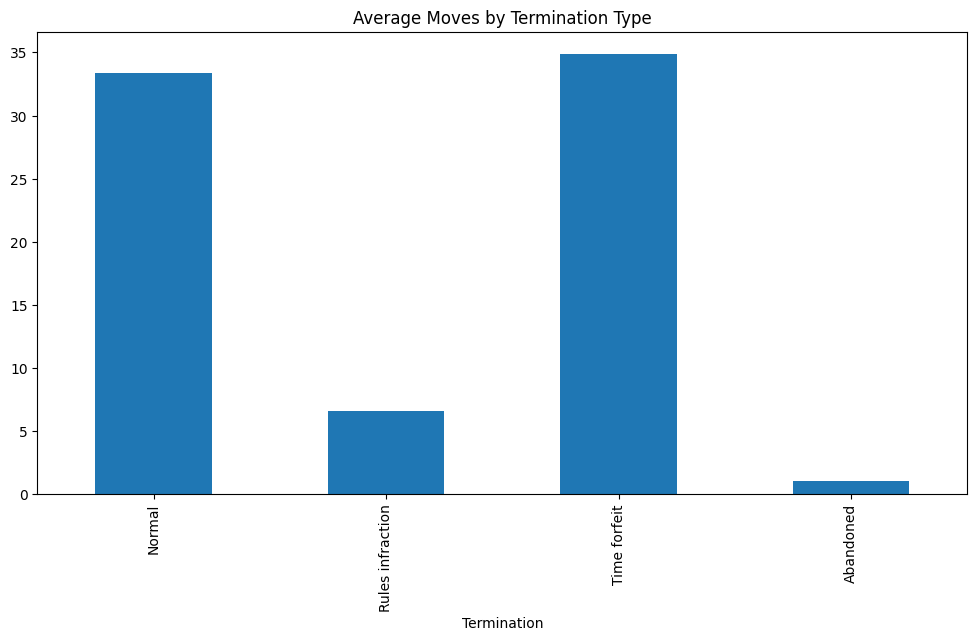

In [24]:
moves_per_termination = ddf.groupby('Termination')['Number_of_Moves'].mean().compute()
moves_per_termination.plot(kind='bar', figsize=(12,6), title='Average Moves by Termination Type')



### Experience using dask 
In this task, I explored how to work with **large datasets** using the **Dask** library.  
- Dask is very efficient for medium-to-large datasets that don’t fit into memory but still can be processed on a single machine or small cluster.  
- For **hundreds of gigabytes or even terabytes**, the recommended tool is **PySpark**, which is designed for enterprise-scale distributed data processing.  

I also experimented with using `dask.distributed.Client` to manage workers and threads. A key learning point was that:
- You need to carefully configure the **number of workers** and **memory limits** based on your hardware.  
- If misconfigured (too many workers or too little memory), computations may run indefinitely or fail.  
- I ran the code below with only 2 workers and 2 threads and 300 MB memory limit. Even though it didn’t run out of memory, the execution took more than 760 minutes and still didn’t produce any results.

Example:
```python
from dask.distributed import Client

client = Client(
    n_workers=2,         
    threads_per_worker=2, 
    memory_limit='300MB'  
)

